# 14.8 - Conservative source-image grouping

Historical calculus validation contains repeated source scenes. Preserve the existing validation membership and remove connected training images. Source test remains unopened. Similarity links are conservative exclusions, not confirmed patient identities.

## 1. Inspect the historical manifest
Use the exact downloaded positive-only baseline inputs. Verify their counts before grouping.

In [1]:
from pathlib import Path
import hashlib, json, re
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists():
    if root == root.parent: raise RuntimeError('Project root unavailable')
    root = root.parent
source = root / 'data/runs/calculus_v3/calculus_data'
report = root / 'docs/reports/calculus_grouped'
report.mkdir(parents=True, exist_ok=True)
records = []
for split in ['train', 'val']:
    for path in sorted((source / 'images' / split).iterdir()):
        label = source / 'labels' / split / (path.stem + '.txt')
        with Image.open(path) as image:
            gray = np.asarray(ImageOps.grayscale(image).resize((9, 8)))
            width, height = image.size
        records.append(dict(name=path.name, original_split=split,
            source_key=re.split(r'\.rf\.', path.stem)[0],
            image_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
            label_sha256=hashlib.sha256(label.read_bytes()).hexdigest(),
            dhash=int.from_bytes(np.packbits(gray[:, 1:] > gray[:, :-1]).tobytes(), 'big'),
            width=width, height=height, boxes=len(label.read_text().splitlines())))
assert Counter(r['original_split'] for r in records) == {'train': 846, 'val': 239}
display(pd.DataFrame(records).groupby('original_split').agg(images=('name','size'), boxes=('boxes','sum')))

,images,boxes
original_split,,
train,846,5898
val,239,1498


## 2. Build conservative connected groups
Link identical bytes, matching pre-Roboflow names and dHash distance <=4 across all retained images. Transitive components touching validation are excluded from training. A dHash match alone is a review candidate. This policy can over-group similar scenes and does not establish patient independence.

,images,boxes,groups
split,,,
excluded,496,2876,108
train,350,3022,201
val,239,1498,145


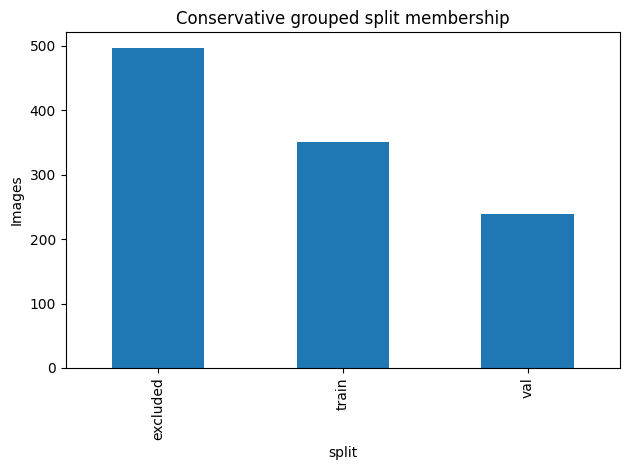

In [2]:
parent = list(range(len(records)))
def find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index
def union(left, right):
    parent[find(left)] = find(right)
edges = []
for left, a in enumerate(records):
    for right in range(left + 1, len(records)):
        b = records[right]
        reasons = []
        if a['image_sha256'] == b['image_sha256']: reasons.append('exact_bytes')
        if a['source_key'] == b['source_key']: reasons.append('source_filename')
        distance = (a['dhash'] ^ b['dhash']).bit_count()
        if distance <= 4: reasons.append('dhash_candidate')
        if reasons:
            union(left, right)
            edges.append(dict(left=left, right=right, distance=distance, reasons='|'.join(reasons)))
validation_groups = {find(i) for i, r in enumerate(records) if r['original_split'] == 'val'}
for i, row in enumerate(records):
    row['group'] = find(i)
    row['split'] = 'val' if row['original_split'] == 'val' else ('excluded' if find(i) in validation_groups else 'train')
frame = pd.DataFrame(records)
assert set(frame.loc[frame.split == 'train', 'group']).isdisjoint(frame.loc[frame.split == 'val', 'group'])
assert (frame.split == 'train').sum() >= 100, 'Insufficient independent training support'
display(frame.groupby('split').agg(images=('name','size'), boxes=('boxes','sum'), groups=('group','nunique')))
frame.groupby('split').size().plot.bar(title='Conservative grouped split membership', ylabel='Images')
plt.tight_layout(); plt.show()

## 3. Inspect excluded scenes
Show representative cross-split candidate pairs. Names and measured distances make the exclusions auditable. These examples do not clinically validate every pair.

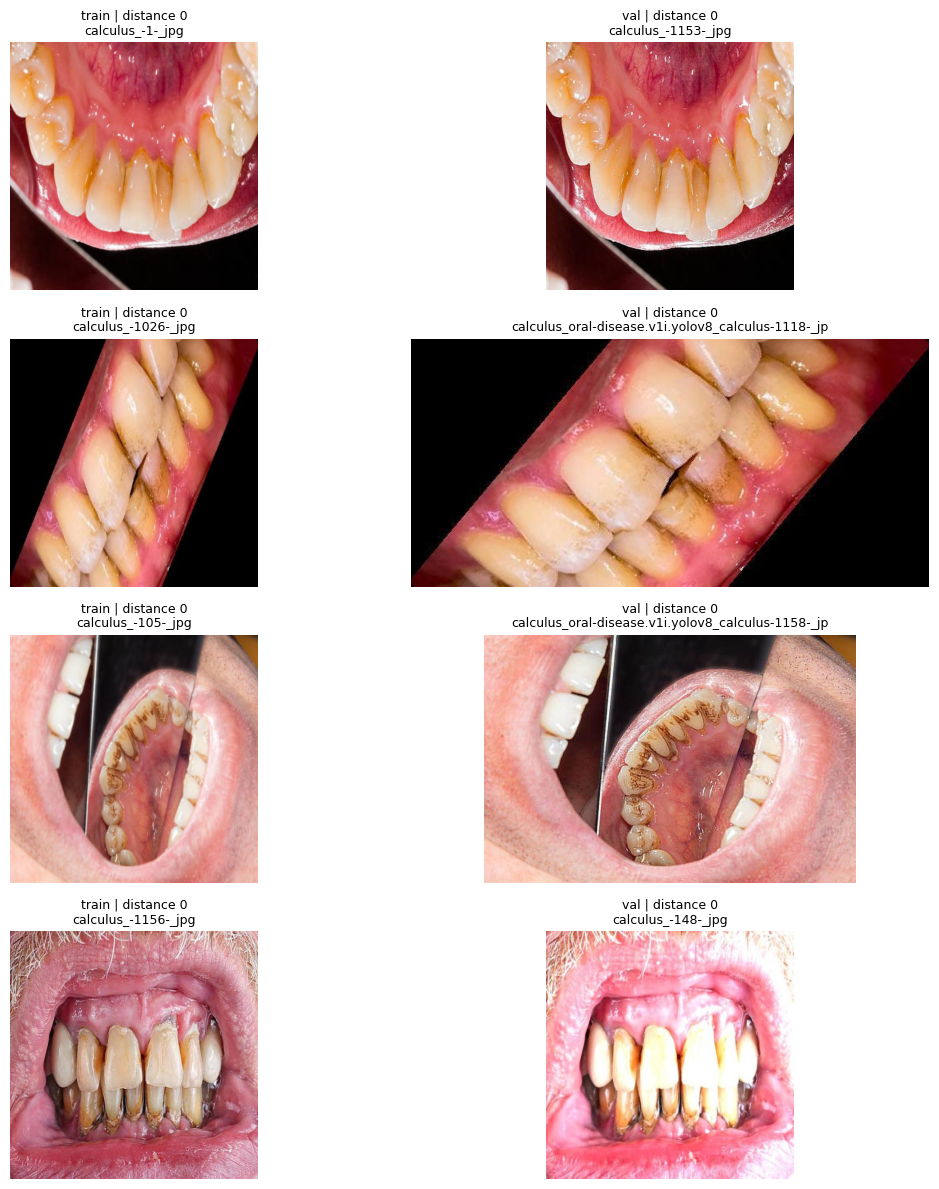

,left,right,distance,reasons
0,0,846,24,source_filename
1,1,846,15,source_filename
2,1,888,0,dhash_candidate
3,2,847,20,source_filename
4,3,847,16,source_filename
5,6,848,17,source_filename
6,10,849,31,source_filename
7,20,850,33,source_filename
8,21,851,3,source_filename|dhash_candidate
9,22,851,31,source_filename


In [3]:
cross = [e for e in edges if records[e['left']]['original_split'] != records[e['right']]['original_split']]
fig, axes = plt.subplots(4, 2, figsize=(12, 12))
for ax in axes.flat: ax.axis('off')
for pair_axes, edge in zip(axes, sorted(cross, key=lambda e: e['distance'])[:4]):
    for ax, key in zip(pair_axes, ['left', 'right']):
        row = records[edge[key]]
        with Image.open(source / 'images' / row['original_split'] / row['name']) as im:
            ax.imshow(im)
        ax.set_title(row['original_split'] + ' | distance ' + str(edge['distance']) + '\n' + row['source_key'][:50], fontsize=9)
plt.tight_layout(); plt.savefig(report / 'candidate_pairs.png'); plt.show()
display(pd.DataFrame(cross).head(12))

## 4. Freeze provenance and split
Save all exclusions, graph edges and image/label checksums. The manifest hash is embedded in both training notebooks. This is a validation development split, with positive-only source images and no patient-level guarantee.

In [4]:
frame.to_csv(report / 'membership.csv', index=False)
pd.DataFrame(edges).to_csv(report / 'group_edges.csv', index=False)
manifest = {'protocol': 'calculus_conservative_groups_v1', 'dhash_threshold': 4,
    'policy': 'keep historical validation; exclude connected training components',
    'source': 'singh868/multi-class-oral-disease-detection-dataset/1',
    'records': [{k:v for k,v in r.items() if k != 'dhash'} for r in records]}
payload = json.dumps(manifest, sort_keys=True, indent=2).encode('utf-8')
(report / 'manifest.json').write_bytes(payload)
digest = hashlib.sha256(payload).hexdigest()
(report / 'manifest.sha256').write_text(digest + '\n')
print('Manifest SHA-256:', digest)
print('Training / validation / excluded:', frame.split.value_counts().to_dict())

Manifest SHA-256: 831e8768df7ed11d7608b008297380a2014be4a1badeb56c21a1d0f70e828a50
Training / validation / excluded: {'excluded': 496, 'train': 350, 'val': 239}
